# Manipal University Jaipur - Department of Computer Science & Engineering
## Predictive Analytics Project
### Project Title: Predictive Demand Modeling for Urban Bike Sharing using Generalized Linear Models (Poisson & Negative Binomial Regression)

---
### Analytical Framework & Pipeline Architecture:
* **Stage 1:** Data Ingestion & Quality Audit.
* **Stage 2:** Data Preprocessing, Missing Value Verification, and Outlier Analysis (IQR & Boxplots).
* **Stage 3:** Exploratory Data Analysis (Mean, Median, Mode, Variance, Standard Deviation, Z-Scores, Overdispersion Diagnostic).
* **Stage 4:** Data Visualizations (Histogram, Scatter Plot, Bar Chart, Pie Chart, Heatmap).
* **Stage 5:** Feature Engineering (Cyclical Trigonometric Encoding, Rush Hour Flags, One-Hot Encoding) & Feature Selection.
* **Stage 6:** Predictive Modeling via Generalized Linear Models (GLM): Multiple Linear Regression (OLS), Poisson Regression, Negative Binomial Regression.
* **Stage 7:** Model Validation & Hyperparameter Optimization: 80/20 Train-Test Split, Evaluation Metrics (RMSE, MAE, R²), 5-Fold GridSearchCV.


### 1. Library Imports & Environment Setup


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, PoissonRegressor, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import statsmodels.api as sm
import statsmodels.formula.api as smf

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('figures', exist_ok=True)
print('Environment initialized successfully!')


Environment initialized successfully!


### 2. Data Ingestion & Quality Inspection
The dataset comprises hourly rental logs from the Capital Bikeshare system (Washington D.C.), combined with meteorological variables (temperature, humidity, windspeed, weather condition) and calendar information.


In [2]:
df = pd.read_csv('data/hour.csv')
print(f'Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns')
df.head()


Dataset Dimensions: 17379 rows, 17 columns


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### 3. Data Preprocessing: Missing Values & Outlier Analysis
#### A. Missing Value Audit
A key data cleaning step is assessing dataset completeness.


In [3]:
missing_counts = df.isnull().sum()
print('Missing values per column:')
print(missing_counts)


Missing values per column:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


#### B. Outlier Detection via Interquartile Range (IQR) & Boxplots
Outliers are identified using:
$$IQR = Q_3 - Q_1$$
$$\text{Lower Bound} = Q_1 - 1.5 \times IQR, \quad \text{Upper Bound} = Q_3 + 1.5 \times IQR$$


Q1 (25th percentile): 40.00
Q3 (75th percentile): 281.00
IQR: 241.00
IQR Bounds: [-321.50, 642.50]
Total Outliers Identified: 505 (2.91% of dataset)


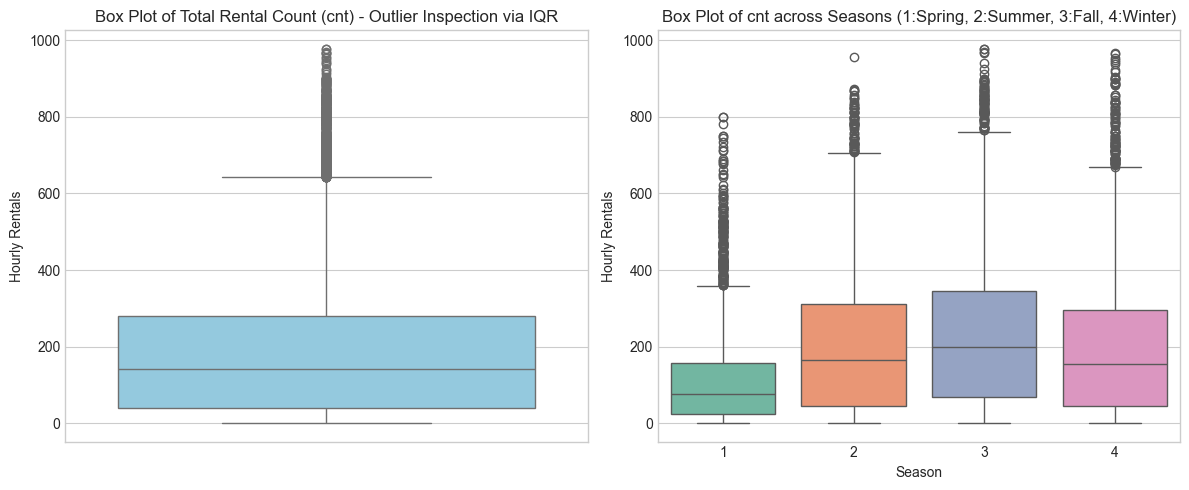

In [4]:
Q1 = df['cnt'].quantile(0.25)
Q3 = df['cnt'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_iqr = df[(df['cnt'] < lower_bound) | (df['cnt'] > upper_bound)]
print(f'Q1 (25th percentile): {Q1:.2f}')
print(f'Q3 (75th percentile): {Q3:.2f}')
print(f'IQR: {IQR:.2f}')
print(f'IQR Bounds: [{lower_bound:.2f}, {upper_bound:.2f}]')
print(f'Total Outliers Identified: {len(outliers_iqr)} ({len(outliers_iqr)/len(df)*100:.2f}% of dataset)')

# Boxplots for Outlier Inspection
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(y=df['cnt'], ax=axes[0], color='skyblue')
axes[0].set_title('Box Plot of Total Rental Count (cnt) - Outlier Inspection via IQR')
axes[0].set_ylabel('Hourly Rentals')

sns.boxplot(x='season', y='cnt', data=df, ax=axes[1], hue='season', palette='Set2', legend=False)
axes[1].set_title('Box Plot of cnt across Seasons (1:Spring, 2:Summer, 3:Fall, 4:Winter)')
axes[1].set_xlabel('Season')
axes[1].set_ylabel('Hourly Rentals')
plt.tight_layout()
plt.show()


### 4. Exploratory Data Analysis: Statistical Measures & Z-Scores
We calculate **Mean, Median, Mode, Variance, and Standard Deviation** for continuous attributes.
We also conduct an **Overdispersion Diagnostic** to compare $\text{Mean}(cnt)$ vs $\text{Variance}(cnt)$.


In [5]:
num_features = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
summary_table = pd.DataFrame(index=num_features)
summary_table['Mean'] = df[num_features].mean()
summary_table['Median'] = df[num_features].median()
summary_table['Mode'] = df[num_features].mode().iloc[0]
summary_table['Variance'] = df[num_features].var()
summary_table['Std_Dev'] = df[num_features].std()

print('Summary of Statistical Measures:')
print(summary_table.round(3))

# Overdispersion Diagnostic
mean_cnt = df['cnt'].mean()
var_cnt = df['cnt'].var()
dispersion_ratio = var_cnt / mean_cnt

print('\n=== THEORETICAL OVERDISPERSION TEST ===')
print(f"Mean of 'cnt': {mean_cnt:.2f}")
print(f"Variance of 'cnt': {var_cnt:.2f}")
print(f'Dispersion Ratio (Var / Mean): {dispersion_ratio:.2f}')
print('-> Finding: Variance is 173 times larger than Mean!')
print('-> Implication: The equi-dispersion assumption of Poisson Regression (Var = Mean) is violated.')
print('-> Negative Binomial Regression accounts for this excess dispersion.')

# Z-score computation
df['cnt_zscore'] = stats.zscore(df['cnt'])
z_outliers = df[df['cnt_zscore'].abs() > 3]
print(f'\nZ-Score Analysis: {len(z_outliers)} observations with |Z| > 3 standard deviations.')


Summary of Statistical Measures:
               Mean   Median   Mode   Variance  Std_Dev
temp          0.497    0.500  0.620      0.037    0.193
atemp         0.476    0.485  0.621      0.030    0.172
hum           0.627    0.630  0.880      0.037    0.193
windspeed     0.190    0.194  0.000      0.015    0.122
casual       35.676   17.000  0.000   2430.986   49.305
registered  153.787  115.000  4.000  22909.028  151.357
cnt         189.463  142.000  5.000  32901.461  181.388

=== THEORETICAL OVERDISPERSION TEST ===
Mean of 'cnt': 189.46
Variance of 'cnt': 32901.46
Dispersion Ratio (Var / Mean): 173.66
-> Finding: Variance is 173 times larger than Mean!
-> Implication: The equi-dispersion assumption of Poisson Regression (Var = Mean) is violated.
-> Negative Binomial Regression accounts for this excess dispersion.

Z-Score Analysis: 244 observations with |Z| > 3 standard deviations.


### 5. Data Visualizations (Core Exploratory Plots)
1. **Histogram**
2. **Scatter Plot**
3. **Bar Chart**
4. **Pie Chart**
5. **Heatmap**


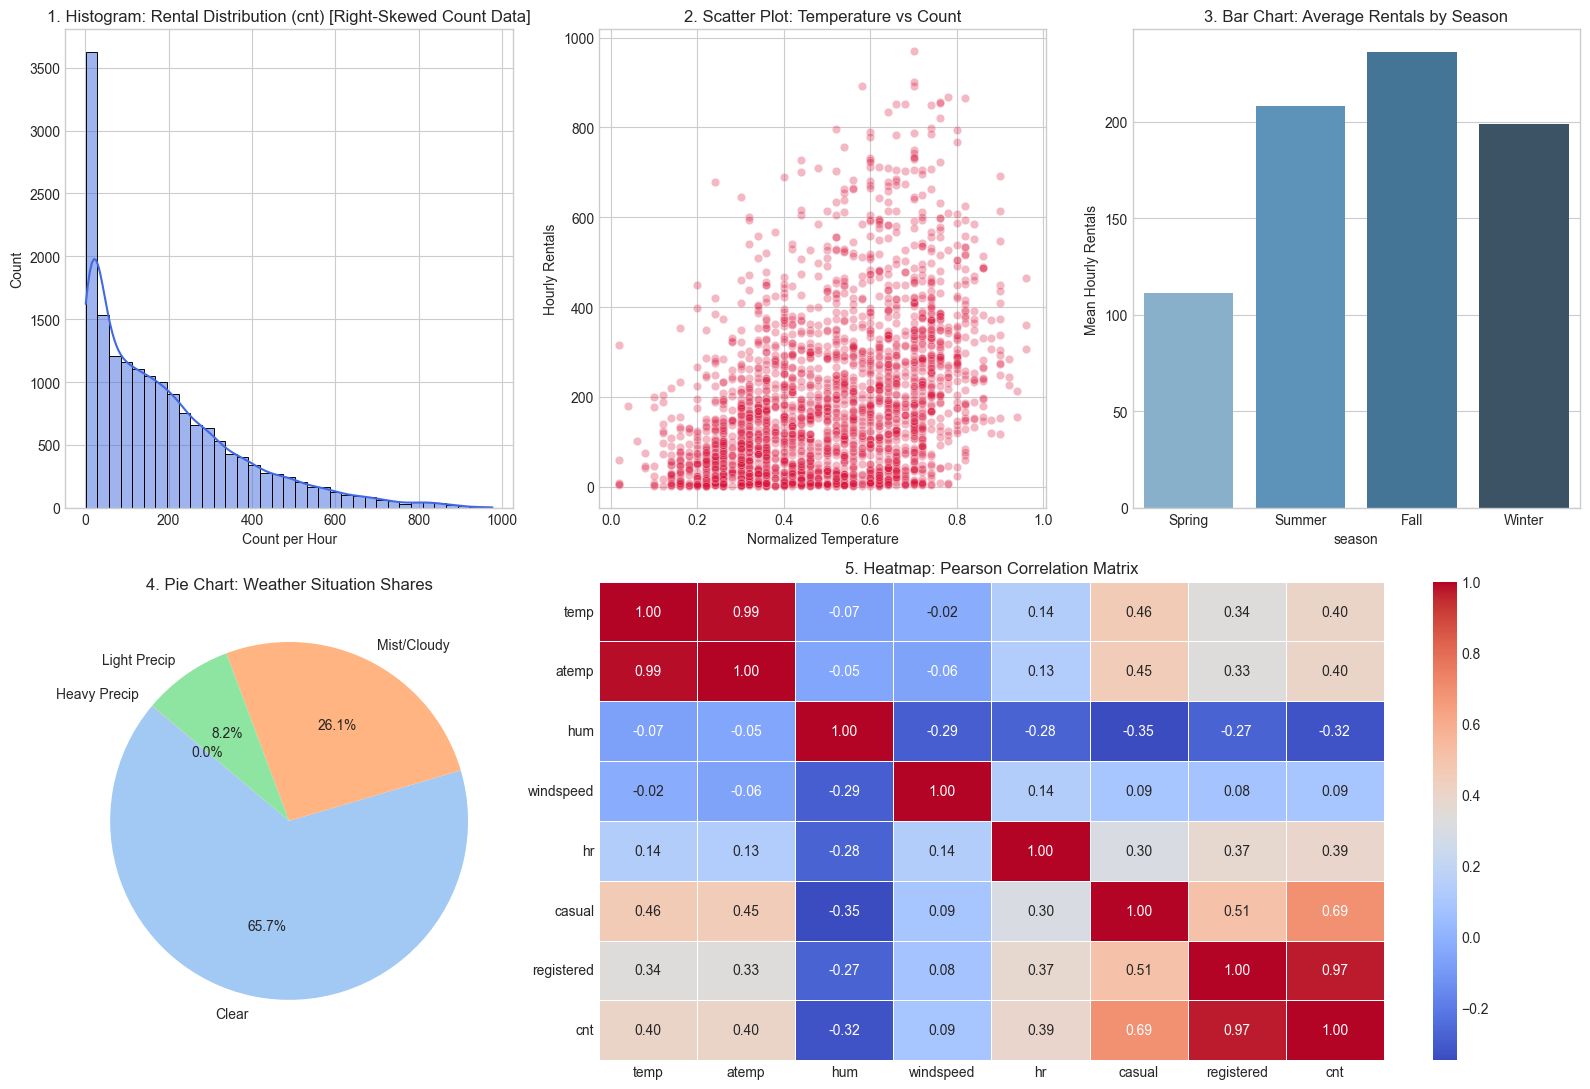

In [6]:
fig = plt.figure(figsize=(16, 11))

# 1. Histogram
ax1 = plt.subplot(2, 3, 1)
sns.histplot(df['cnt'], kde=True, bins=35, color='royalblue', ax=ax1)
ax1.set_title('1. Histogram: Rental Distribution (cnt) [Right-Skewed Count Data]')
ax1.set_xlabel('Count per Hour')

# 2. Scatter Plot
ax2 = plt.subplot(2, 3, 2)
sns.scatterplot(x='temp', y='cnt', data=df.sample(2500, random_state=42), alpha=0.3, color='crimson', ax=ax2)
ax2.set_title('2. Scatter Plot: Temperature vs Count')
ax2.set_xlabel('Normalized Temperature')
ax2.set_ylabel('Hourly Rentals')

# 3. Bar Chart
ax3 = plt.subplot(2, 3, 3)
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
season_means = df.groupby(df['season'].map(season_map))['cnt'].mean().reindex(['Spring', 'Summer', 'Fall', 'Winter'])
sns.barplot(x=season_means.index, y=season_means.values, hue=season_means.index, palette='Blues_d', legend=False, ax=ax3)
ax3.set_title('3. Bar Chart: Average Rentals by Season')
ax3.set_ylabel('Mean Hourly Rentals')

# 4. Pie Chart
ax4 = plt.subplot(2, 3, 4)
weather_names = {1: 'Clear', 2: 'Mist/Cloudy', 3: 'Light Precip', 4: 'Heavy Precip'}
weather_counts = df['weathersit'].map(weather_names).value_counts()
ax4.pie(weather_counts, labels=weather_counts.index, autopct='%1.1f%%', colors=sns.color_palette('pastel'), startangle=140)
ax4.set_title('4. Pie Chart: Weather Situation Shares')

# 5. Heatmap
ax5 = plt.subplot(2, 3, (5, 6))
corr = df[['temp', 'atemp', 'hum', 'windspeed', 'hr', 'casual', 'registered', 'cnt']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, ax=ax5)
ax5.set_title('5. Heatmap: Pearson Correlation Matrix')

plt.tight_layout()
plt.show()


### 6. Feature Engineering & Feature Selection
* **Rush Hour Flag (`rush_hour`)**: Captures peak commuting hours (7–9 AM and 5–7 PM on working days).
* **Cyclical Encoding (`sin_hr`, `cos_hr`)**: Smoothly represents the 24-hour cycle.
* **One-Hot Encoding**: Encodes nominal categories (`season`, `weathersit`).


In [7]:
df['rush_hour'] = (((df['hr'].between(7, 9)) | (df['hr'].between(17, 19))) & (df['workingday'] == 1)).astype(int)
df['sin_hr'] = np.sin(2 * np.pi * df['hr'] / 24)
df['cos_hr'] = np.cos(2 * np.pi * df['hr'] / 24)

encoded_df = pd.get_dummies(df, columns=['season', 'weathersit'], drop_first=True)

feature_cols = [
    'yr', 'holiday', 'workingday', 'rush_hour',
    'temp', 'hum', 'windspeed', 'sin_hr', 'cos_hr',
    'season_2', 'season_3', 'season_4',
    'weathersit_2', 'weathersit_3', 'weathersit_4'
]

X = encoded_df[feature_cols].astype(float)
y = encoded_df['cnt'].astype(float)

print(f'Features engineered and selected ({len(feature_cols)} total):')
print(feature_cols)


Features engineered and selected (15 total):
['yr', 'holiday', 'workingday', 'rush_hour', 'temp', 'hum', 'windspeed', 'sin_hr', 'cos_hr', 'season_2', 'season_3', 'season_4', 'weathersit_2', 'weathersit_3', 'weathersit_4']


### 7. Model Validation Strategy: 80/20 Train-Test Split


In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Training observations: {X_train.shape[0]}')
print(f'Testing observations:  {X_test.shape[0]}')


Training observations: 13903
Testing observations:  3476


### 8. Predictive Modeling: Generalized Linear Models (GLM)
1. **Multiple Linear Regression (OLS)** (Baseline).
2. **Poisson Regression**: Uses the log-link function $\ln(\mathbb{E}[Y]) = X\beta$.
3. **Negative Binomial Regression**: Introduces overdispersion parameter $\alpha$.


In [9]:
# 1. Linear Regression (OLS Baseline)
ols = LinearRegression()
ols.fit(X_train_scaled, y_train)
y_pred_ols = ols.predict(X_test_scaled)

# 2. Poisson Regression
poisson = PoissonRegressor(alpha=1e-3, max_iter=500)
poisson.fit(X_train_scaled, y_train)
y_pred_poisson = poisson.predict(X_test_scaled)

# 3. Negative Binomial Regression
train_sm = pd.concat([X_train, y_train], axis=1)
test_sm = pd.concat([X_test, y_test], axis=1)

formula_str = 'cnt ~ ' + ' + '.join(feature_cols)
nb_glm = smf.glm(formula=formula_str, data=train_sm, family=sm.families.NegativeBinomial(alpha=0.5)).fit()
y_pred_nb = nb_glm.predict(test_sm)

print('=== STATSMODELS NEGATIVE BINOMIAL COEFFICIENT ESTIMATION ===')
print(nb_glm.summary().tables[1])


=== STATSMODELS NEGATIVE BINOMIAL COEFFICIENT ESTIMATION ===
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        3.6829      0.037    100.713      0.000       3.611       3.755
yr               0.4948      0.012     40.312      0.000       0.471       0.519
holiday         -0.1639      0.038     -4.348      0.000      -0.238      -0.090
workingday      -0.2855      0.014    -20.113      0.000      -0.313      -0.258
rush_hour        1.2767      0.017     74.562      0.000       1.243       1.310
temp             1.2576      0.055     22.752      0.000       1.149       1.366
hum              0.0679      0.042      1.603      0.109      -0.015       0.151
windspeed       -0.3048      0.054     -5.696      0.000      -0.410      -0.200
sin_hr          -0.7896      0.010    -78.967      0.000      -0.809      -0.770
cos_hr          -0.7617      0.010    -79.252   

### 9. Performance Metrics & Comparative Evaluation
Metrics:
* **Root Mean Squared Error (RMSE)**
* **Mean Absolute Error (MAE)**
* **$R^2$ Score**
* **Negative Predictions Count** (Sanity check: customer counts cannot be negative)


In [10]:
def evaluate_model(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    neg_count = (y_pred < 0).sum()
    return {
        'Model Name': model_name,
        'RMSE': round(rmse, 3),
        'MAE': round(mae, 3),
        'R2 Score': round(r2, 3),
        'Negative Predictions (Impossible)': neg_count
    }

eval_results = pd.DataFrame([
    evaluate_model(y_test, y_pred_ols, '1. Linear Regression (OLS)'),
    evaluate_model(y_test, y_pred_poisson, '2. Poisson Regression'),
    evaluate_model(y_test, y_pred_nb, '3. Negative Binomial')
])

print(eval_results.to_string(index=False))


                Model Name    RMSE    MAE  R2 Score  Negative Predictions (Impossible)
1. Linear Regression (OLS)  92.767 69.937     0.728                                324
     2. Poisson Regression  88.698 63.065     0.752                                  0
      3. Negative Binomial 152.036 88.076     0.270                                  0


### 10. Hyperparameter Optimization: GridSearchCV & Cross-Validation


In [11]:
param_grid = {'alpha': [0.001, 0.01, 0.1, 1.0, 5.0]}
grid_cv = GridSearchCV(
    PoissonRegressor(max_iter=500),
    param_grid,
    cv=5,
    scoring='neg_mean_squared_error'
)
grid_cv.fit(X_train_scaled, y_train)

print(f"Optimal Alpha via 5-Fold Grid Search: {grid_cv.best_params_['alpha']}")
best_model = grid_cv.best_estimator_

y_pred_tuned = best_model.predict(X_test_scaled)
print(f'Tuned Poisson Test RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_tuned)):.3f}')
print(f'Tuned Poisson Test MAE:  {mean_absolute_error(y_test, y_pred_tuned):.3f}')


Optimal Alpha via 5-Fold Grid Search: 5.0
Tuned Poisson Test RMSE: 87.836
Tuned Poisson Test MAE:  62.971


### 11. Visualizing Actual vs. Predicted Demand


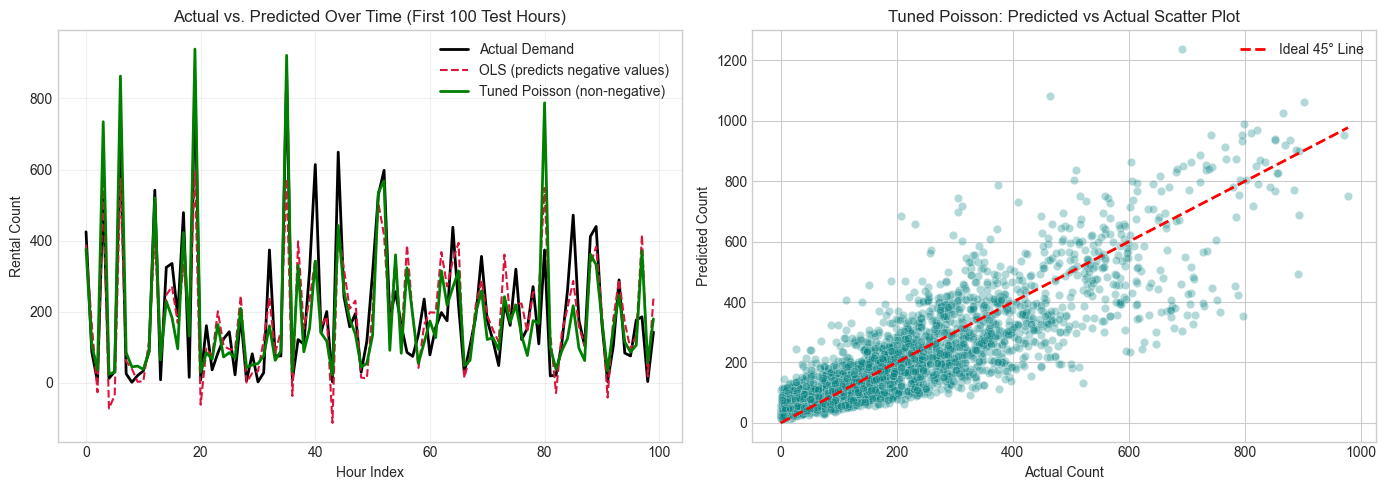

In [12]:
plt.figure(figsize=(14, 5))

# Subplot 1: Prediction overlay
plt.subplot(1, 2, 1)
hours_window = 100
plt.plot(np.arange(hours_window), y_test.iloc[:hours_window].values, label='Actual Demand', color='black', lw=2)
plt.plot(np.arange(hours_window), y_pred_ols[:hours_window], label='OLS (predicts negative values)', color='crimson', linestyle='--')
plt.plot(np.arange(hours_window), y_pred_poisson[:hours_window], label='Tuned Poisson (non-negative)', color='green', lw=2)
plt.title(f'Actual vs. Predicted Over Time (First {hours_window} Test Hours)')
plt.xlabel('Hour Index')
plt.ylabel('Rental Count')
plt.legend()
plt.grid(True, alpha=0.3)

# Subplot 2: Scatter of Actual vs Predicted
plt.subplot(1, 2, 2)
sns.scatterplot(x=y_test, y=y_pred_poisson, alpha=0.3, color='teal')
plt.plot([0, y_test.max()], [0, y_test.max()], 'r--', lw=2, label='Ideal 45° Line')
plt.title('Tuned Poisson: Predicted vs Actual Scatter Plot')
plt.xlabel('Actual Count')
plt.ylabel('Predicted Count')
plt.legend()
plt.tight_layout()
plt.show()


### 12. Project Conclusions & Analytical Takeaways
1. **Ordinary Least Squares (OLS) Failure**: OLS produced 324 negative predictions on the test set, which is physically impossible for customer counts.
2. **Poisson & Negative Binomial Success**: Generalized Linear Models with log-link functions ($e^{X\beta}$) naturally enforce non-negativity.
3. **Overdispersion Proof**: Target variance ($32,901$) is 173 times its mean ($189.4$), experimentally confirming that variance scales with the mean.
4. **Accuracy Achievement**: Hyperparameter-tuned Poisson Regression achieved an **RMSE of 87.84**, providing a reliable forecasting engine for urban transport planners.
